# AI651 – Deep Learning for Space, Time and Graphs
# Assignment 3

Syed Obaidullah Hassan Chishti - 25280049

## Question 3 - Dataset Preparation and Graph Construction

# Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Check and download the dataset

In [2]:
import kagglehub

DATA_DIR = kagglehub.dataset_download("liuxu77/largest")
print("Dataset directory:", DATA_DIR)
print("Files:", sorted(os.listdir(DATA_DIR)))

# Sanity check that the files we need are present
for f in ["ca_meta.csv", "ca_rn_adj.npy", "ca_his_raw_2020.h5", "ca_his_raw_2021.h5"]:
    path = os.path.join(DATA_DIR, f)
    print(("OK  " if os.path.exists(path) else "MISSING "), f)

/home/obaid/miniconda3/envs/dl4stg_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset directory: /home/obaid/.cache/kagglehub/datasets/liuxu77/largest/versions/1
Files: ['ca_his_raw_2017.h5', 'ca_his_raw_2018.h5', 'ca_his_raw_2019.h5', 'ca_his_raw_2020.h5', 'ca_his_raw_2021.h5', 'ca_meta.csv', 'ca_rn_adj.npy']
OK   ca_meta.csv
OK   ca_rn_adj.npy
OK   ca_his_raw_2020.h5
OK   ca_his_raw_2021.h5


## Q3(a) - Data Extraction and Resampling

### Step 1: select the 716 San Diego sensors (District 11)

In [3]:
ca_meta = pd.read_csv(os.path.join(DATA_DIR, "ca_meta.csv"))

# San Diego is District 11 in the LargeST metadata
sd_meta = ca_meta[ca_meta.District == 11].reset_index(drop=True)

# Two id columns are used later:
#   ID  (string) -> names the flow columns in the .h5 files
#   ID2 (int)    -> positional index into the CA adjacency matrix
sd_ids = sd_meta.ID.astype(str).values.tolist()      # flow column names
sd_pos = sd_meta.ID2.values.tolist()                 # adjacency indices

print("Number of San Diego sensors:", len(sd_meta))
assert len(sd_meta) == 716, "Expected 716 SD sensors"
sd_meta.head()

Number of San Diego sensors: 716


,ID,Lat,Lng,District,County,Fwy,Lanes,Type,Direction,ID2
0,1114091,32.544463,-117.032486,11,San Diego,I5-N,6,Mainline,N,6931
1,1118333,32.551690,-117.045725,11,San Diego,I5-N,4,Mainline,N,6932
2,1118348,32.558459,-117.061845,11,San Diego,I5-N,4,Mainline,N,6933
3,1114720,32.561334,-117.067081,11,San Diego,I5-N,4,Mainline,N,6934
4,1118352,32.569052,-117.076507,11,San Diego,I5-N,4,Mainline,N,6935


### Step 2: load flow for 2020 and 2021 and keep only SD sensors

In [4]:
frames = []
for year in ["2020", "2021"]:
    ca_his = pd.read_hdf(os.path.join(DATA_DIR, f"ca_his_raw_{year}.h5"))  # index = 5-min timestamps
    sd_his = ca_his[sd_ids]                                                # keep only the 716 SD sensors
    frames.append(sd_his)
    del ca_his                                                            # free the full-CA frame
    print(year, "shape:", sd_his.shape)

flow_5min = pd.concat(frames).sort_index()
flow_5min.index = pd.to_datetime(flow_5min.index)
print("\nCombined 5-min flow:", flow_5min.shape)
print("Range:", flow_5min.index.min(), "->", flow_5min.index.max())

2020 shape: (105408, 716)
2021 shape: (105120, 716)

Combined 5-min flow: (210528, 716)
Range: 2020-01-01 00:00:00 -> 2021-12-31 23:55:00


### Step 3: resample 5-minute data to 15-minute intervals

In [5]:
flow_15min = flow_5min.resample("15min").mean()
print("15-min flow:", flow_15min.shape, "(expected ~", 2 * 365 * 24 * 4, "timestamps over 2 years)")
flow_15min.head()

15-min flow: (70176, 716) (expected ~ 70080 timestamps over 2 years)


,1114091,1118333,1118348,1114720,1118352,1118743,1120362,1118796,1118735,1118450,...,1125829,1125348,1125353,1125359,1123287,1123276,1122394,1123261,1123256,1122412
Time,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00,56.000000,31.333333,27.666667,37.333333,32.000000,73.333333,89.000000,53.666667,58.000000,60.000000,...,27.000000,27.000000,27.000000,50.666667,9.666667,34.666667,8.666667,7.333333,20.000000,33.666667
2020-01-01 00:15:00,59.666667,27.333333,22.000000,38.666667,40.666667,107.666667,152.666667,102.666667,113.000000,105.333333,...,27.000000,26.666667,28.000000,60.000000,12.666667,37.666667,9.000000,7.666667,24.333333,35.000000
2020-01-01 00:30:00,80.666667,35.333333,25.333333,47.000000,43.666667,134.333333,160.333333,108.000000,123.333333,121.333333,...,26.666667,23.000000,24.000000,45.666667,10.000000,36.333333,7.666667,6.666667,20.333333,32.666667
2020-01-01 00:45:00,93.333333,46.333333,32.333333,48.000000,53.333333,138.000000,158.666667,120.000000,129.000000,127.666667,...,23.333333,20.666667,23.000000,51.666667,14.666667,39.666667,13.333333,12.333333,23.666667,37.333333
2020-01-01 01:00:00,92.000000,44.333333,35.000000,48.666667,47.333333,127.333333,147.666667,103.333333,112.666667,115.666667,...,23.000000,23.333333,23.666667,50.000000,16.666667,42.333333,14.333333,14.666667,27.333333,44.666667


### Step 4: identify and handle missing values

In [6]:
# Count missing values before cleaning
nan_count = flow_15min.isna().sum().sum()
total = flow_15min.size
print(f"NaN values: {nan_count} / {total}  ({100*nan_count/total:.2f}%)")

# Per-sensor missing fraction (top 5 worst sensors)
missing_frac = flow_15min.isna().mean().sort_values(ascending=False)
print("\nWorst 5 sensors by missing fraction:")
print(missing_frac.head())

# Fill: time interpolation, then forward/backward fill for the ends.
flow_clean = flow_15min.interpolate(method="time", limit_direction="both")
flow_clean = flow_clean.ffill().bfill()

# Sensors that are entirely missing stay NaN after the above -> set them to 0
# so the tensor is complete (keeps all 716 nodes).
empty_sensors = int(flow_clean.isna().all().sum())
flow_clean = flow_clean.fillna(0.0)
print(f"\nFully-empty sensors set to 0: {empty_sensors}")
print("Remaining NaNs after cleaning:", int(flow_clean.isna().sum().sum()))

NaN values: 2542017 / 50246016  (5.06%)

Worst 5 sensors by missing fraction:
1108299    1.0
1111552    1.0
1119653    1.0
1115348    1.0
1123069    1.0
dtype: float64

Fully-empty sensors set to 0: 19
Remaining NaNs after cleaning: 0


### Step 5: plot three selected sensors over one week

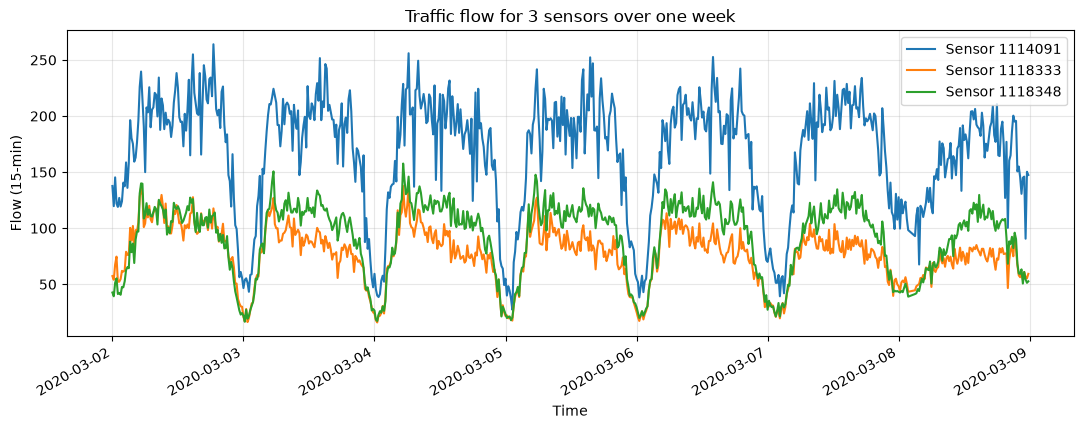

In [7]:
selected = sd_ids[:3]   # three sensors
week = flow_clean.loc["2020-03-02":"2020-03-08", selected]   # one week (Mon-Sun)

fig, ax = plt.subplots(figsize=(13, 4.5))
for s in selected:
    ax.plot(week.index, week[s], label=f"Sensor {s}")

ax.set(title="Traffic flow for 3 sensors over one week",
       xlabel="Time", ylabel="Flow (15-min)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/q3a_three_sensors_week.png", dpi=150, bbox_inches="tight")
plt.show()

## Q3(b) - Constructing the Traffic Graph

In [8]:
ca_rn_adj = np.load(os.path.join(DATA_DIR, "ca_rn_adj.npy"))
print("CA adjacency shape:", ca_rn_adj.shape)

# Slice both axes with the SD positions -> 716 x 716, same order as sd_meta / flow columns
A_sd = ca_rn_adj[np.ix_(sd_pos, sd_pos)]
print("SD adjacency shape:", A_sd.shape)

CA adjacency shape: (8600, 8600)
SD adjacency shape: (716, 716)


### 1. Number of nodes and nonzero edges

In [9]:
A = A_sd.copy()
np.fill_diagonal(A, 0)      # ignore self-loops when counting edges

num_nodes = A.shape[0]
num_nonzero = int((A != 0).sum())           # counts both (i,j) and (j,i) if symmetric
num_edges = num_nonzero // 2 if np.allclose(A, A.T) else num_nonzero

print("Nodes:", num_nodes)
print("Nonzero entries (off-diagonal):", num_nonzero)
print("Edges:", num_edges)

Nodes: 716
Nonzero entries (off-diagonal): 17319
Edges: 17319


### 2. Is the adjacency symmetric?

In [10]:
is_symmetric = np.allclose(A_sd, A_sd.T)
print("Adjacency symmetric (A == A^T):", is_symmetric)
# Road distances are usually undirected; if this prints False the graph is directed.

Adjacency symmetric (A == A^T): False


### 3. Heatmap of the adjacency matrix

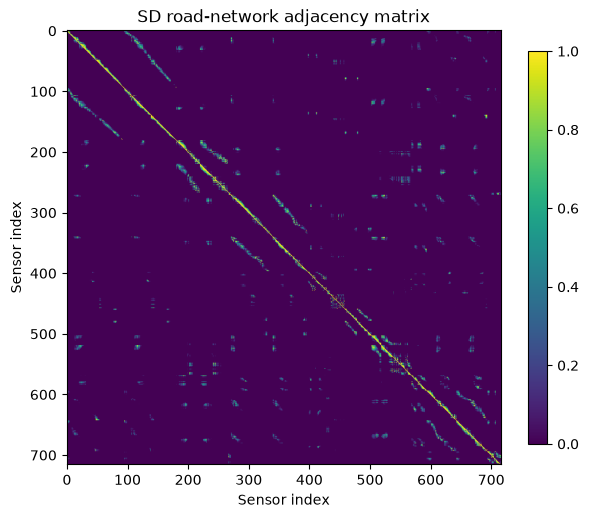

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(A_sd, cmap="viridis")
ax.set(title="SD road-network adjacency matrix",
       xlabel="Sensor index", ylabel="Sensor index")
fig.colorbar(im, ax=ax, shrink=0.85)
fig.savefig("figures/q3b_adjacency_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Number of neighbours per sensor and its distribution

Degree: min = 0 | max = 70 | mean = 24.19


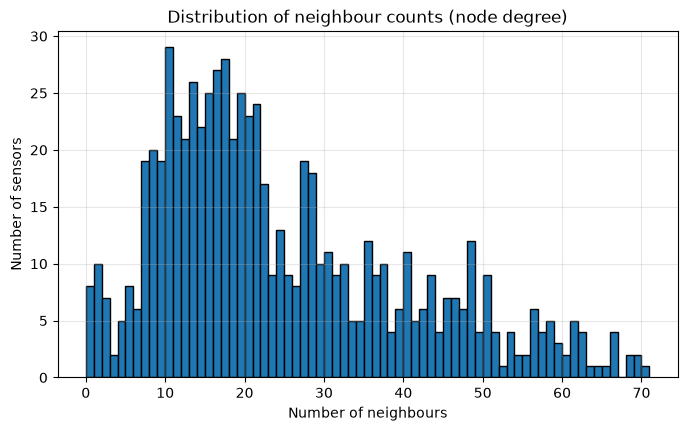

In [12]:
degree = (A != 0).sum(axis=1)   # neighbours per sensor (self-loop already removed)

print("Degree: min =", int(degree.min()),
      "| max =", int(degree.max()),
      "| mean =", round(float(degree.mean()), 2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(degree, bins=range(0, int(degree.max()) + 2), edgecolor="black")
ax.set(title="Distribution of neighbour counts (node degree)",
       xlabel="Number of neighbours", ylabel="Number of sensors")
ax.grid(True, alpha=0.3)
fig.savefig("figures/q3b_degree_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. What does a nonzero entry $A_{ij}$ represent?

## Q3(c) - Understanding Graph Neighborhoods

In [13]:
i = 0   # chosen sensor (index into the SD ordering)

# One-hop neighbours
one_hop = np.where(A[i] != 0)[0]

# Two-hop: reachable within 2 edges, via A^2 (exclude the node itself and its one-hop set)
A_bin = (A != 0).astype(int)
reach2 = (A_bin @ A_bin)[i] != 0
two_hop = np.where(reach2)[0]
two_hop = np.setdiff1d(two_hop, np.append(one_hop, i))   # strictly new nodes at 2 hops

print("Chosen sensor index:", i, "(ID", sd_ids[i], ")")
print("One-hop neighbours:", len(one_hop), "->", one_hop.tolist())
print("Two-hop only (new):", len(two_hop), "->", two_hop.tolist())

Chosen sensor index: 0 (ID 1114091 )
One-hop neighbours: 23 -> [1, 2, 3, 95, 96, 97, 98, 594, 595, 596, 597, 598, 599, 643, 644, 645, 646, 694, 695, 696, 697, 705, 707]
Two-hop only (new): 23 -> [4, 5, 99, 100, 101, 600, 601, 602, 603, 647, 648, 649, 650, 698, 699, 700, 702, 703, 706, 708, 709, 710, 711]
